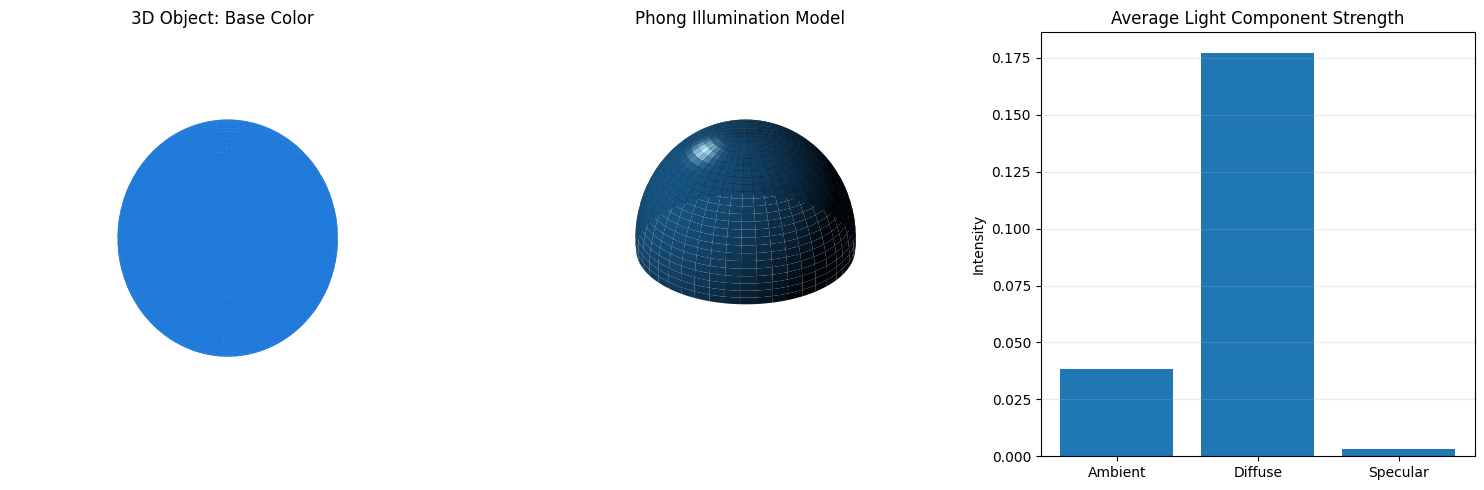

Phong illumination model executed successfully.
Ambient coefficient (ka): 0.18
Diffuse coefficient (kd): 0.72
Specular coefficient (ks): 0.65
Shininess exponent: 40
Phong model: I = Ia*ka + Id*kd*max(N·L, 0) + Is*ks*max(R·V, 0)^n


In [1]:
# Experiment 7: Phong Illumination Model for a 3D Object
# Interactive-style visualization of ambient, diffuse, and specular lighting on a sphere.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource

# Sphere geometry
u = np.linspace(0, 2 * np.pi, 180)
v = np.linspace(0, np.pi, 100)
U, V = np.meshgrid(u, v)

X = np.cos(U) * np.sin(V)
Y = np.sin(U) * np.sin(V)
Z = np.cos(V)

# Surface normals for a unit sphere
normals = np.stack((X, Y, Z), axis=-1)
normals /= np.maximum(np.linalg.norm(normals, axis=-1, keepdims=True), 1e-12)

# Phong illumination parameters
ka = 0.18                 # Ambient reflection coefficient
kd = 0.72                 # Diffuse reflection coefficient
ks = 0.65                 # Specular reflection coefficient
shininess = 40            # Specular shininess exponent

ambient_light = np.array([0.20, 0.20, 0.24])
light_color = np.array([1.0, 0.92, 0.78])
object_color = np.array([0.12, 0.48, 0.85])

# Light and viewer directions
light_position = np.array([-3.0, -4.0, 5.0])
light_position /= np.linalg.norm(light_position)
view_direction = np.array([0.0, 0.0, 1.0])
view_direction /= np.linalg.norm(view_direction)

# Ambient component
ambient = ka * ambient_light

# Diffuse component: kd * max(N dot L, 0)
ndotl = np.maximum(np.sum(normals * light_position, axis=-1), 0.0)
diffuse = kd * ndotl[..., None] * light_color

# Specular component: ks * max(R dot V, 0)^shininess
reflection = 2.0 * ndotl[..., None] * normals - light_position
rdotv = np.maximum(np.sum(reflection * view_direction, axis=-1), 0.0)
specular = ks * (rdotv ** shininess)[..., None] * light_color

# Combine components and apply the object's base color
illumination = ambient + diffuse
rgb = object_color * illumination + specular
rgb = np.clip(rgb, 0.0, 1.0)

# Hide the back half of the sphere for a clean surface rendering
visible = Z >= -0.02
facecolors = np.zeros((*X.shape, 4))
facecolors[..., :3] = rgb
facecolors[..., 3] = visible.astype(float)

fig = plt.figure(figsize=(15, 5))

ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax1.plot_surface(X, Y, Z, color=object_color, linewidth=0, antialiased=True, shade=False)
ax1.set_title("3D Object: Base Color")
ax1.set_box_aspect((1, 1, 1))
ax1.set_axis_off()

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
ax2.plot_surface(X, Y, Z, facecolors=facecolors, linewidth=0, antialiased=True, shade=False)
ax2.set_title("Phong Illumination Model")
ax2.set_box_aspect((1, 1, 1))
ax2.set_axis_off()

ax3 = fig.add_subplot(1, 3, 3)
components = ["Ambient", "Diffuse", "Specular"]
strengths = [
    float(np.mean(ambient)),
    float(np.mean(diffuse)),
    float(np.mean(specular))
]
ax3.bar(components, strengths)
ax3.set_title("Average Light Component Strength")
ax3.set_ylabel("Intensity")
ax3.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

print("Phong illumination model executed successfully.")
print(f"Ambient coefficient (ka): {ka}")
print(f"Diffuse coefficient (kd): {kd}")
print(f"Specular coefficient (ks): {ks}")
print(f"Shininess exponent: {shininess}")
print("Phong model: I = Ia*ka + Id*kd*max(N·L, 0) + Is*ks*max(R·V, 0)^n")


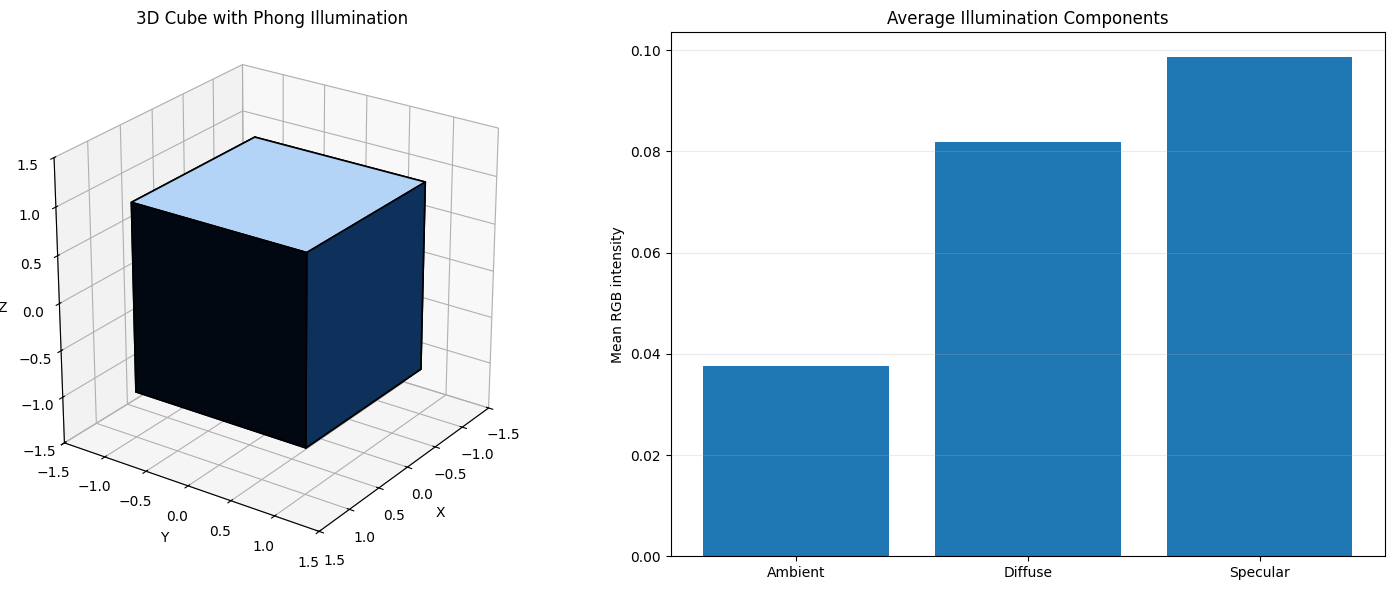

Phong illumination model completed successfully.
Ambient coefficient (ka): 0.22
Diffuse coefficient (kd): 0.7
Specular coefficient (ks): 0.65
Shininess exponent: 32
Phong model: I = ka*Ia*Od + kd*Id*Od*max(N·L,0) + ks*Is*max(R·V,0)^n


In [3]:
# Experiment 7: Phong Illumination Model for a 3D Cube
# Runs in Jupyter Notebook and Google Colab without OpenGL/GLUT.

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Cube vertices and triangular faces
vertices = np.array([
    [-1, -1, -1], [ 1, -1, -1], [ 1,  1, -1], [-1,  1, -1],
    [-1, -1,  1], [ 1, -1,  1], [ 1,  1,  1], [-1,  1,  1]
], dtype=float)

faces = [
    [0, 3, 2, 1],  # back
    [4, 5, 6, 7],  # front
    [0, 1, 5, 4],  # bottom
    [2, 3, 7, 6],  # top
    [1, 2, 6, 5],  # right
    [0, 4, 7, 3]   # left
]

# Phong illumination parameters
ka = 0.22                 # ambient coefficient
kd = 0.70                 # diffuse coefficient
ks = 0.65                 # specular coefficient
shininess = 32            # shininess exponent
object_color = np.array([0.12, 0.42, 0.85])
light_color = np.array([1.0, 0.95, 0.85])
ambient_light = np.array([0.35, 0.35, 0.38])
light_position = np.array([-3.0, 4.0, 5.0])
view_position = np.array([4.0, -5.0, 6.0])

light_position = light_position / np.linalg.norm(light_position)
view_position = view_position / np.linalg.norm(view_position)

def phong_shading(normal):
    """Calculate ambient + diffuse + specular illumination for a face."""
    normal = np.asarray(normal, dtype=float)
    normal /= np.linalg.norm(normal)

    # Direction from surface toward the light and viewer
    L = light_position
    V = view_position

    # Ambient term
    ambient = ka * ambient_light * object_color

    # Diffuse term
    ndotl = max(np.dot(normal, L), 0.0)
    diffuse = kd * ndotl * light_color * object_color

    # Specular term (Phong reflection vector)
    R = 2.0 * np.dot(normal, L) * normal - L
    R /= max(np.linalg.norm(R), 1e-12)
    spec_factor = max(np.dot(R, V), 0.0) ** shininess if ndotl > 0 else 0.0
    specular = ks * spec_factor * light_color

    return np.clip(ambient + diffuse + specular, 0.0, 1.0), (
        ambient, diffuse, specular
    )

fig = plt.figure(figsize=(15, 6))
ax = fig.add_subplot(1, 2, 1, projection="3d")

component_means = np.zeros(3)
for face in faces:
    points = vertices[face]
    # Flat-shaded cube face normal from two edge vectors
    normal = np.cross(points[1] - points[0], points[2] - points[0])
    normal = normal / np.linalg.norm(normal)

    color, components = phong_shading(normal)
    component_means += [np.mean(components[0]), np.mean(components[1]),
                        np.mean(components[2])]

    # Draw the actual 3D polygon face with Phong-computed color
    ax.add_collection3d(
        Poly3DCollection(
            [points],
            facecolors=[color],
            edgecolors="black",
            linewidths=1.2
        )
    )

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_zlim(-1.5, 1.5)
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=25, azim=35)
ax.set_title("3D Cube with Phong Illumination")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

# Display the three illumination components
ax2 = fig.add_subplot(1, 2, 2)
labels = ["Ambient", "Diffuse", "Specular"]
component_means /= len(faces)
ax2.bar(labels, component_means)
ax2.set_title("Average Illumination Components")
ax2.set_ylabel("Mean RGB intensity")
ax2.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

print("Phong illumination model completed successfully.")
print(f"Ambient coefficient (ka): {ka}")
print(f"Diffuse coefficient (kd): {kd}")
print(f"Specular coefficient (ks): {ks}")
print(f"Shininess exponent: {shininess}")
print("Phong model: I = ka*Ia*Od + kd*Id*Od*max(N·L,0) + ks*Is*max(R·V,0)^n")
